# Solution

**Team:** Cache Stackers  
**Task:** Predict the probability that each enquiry reaches the Quote, Prospect, Inspection, and Accepted stages.

This notebook trains the final model pipeline from the provided data and creates `submission_final.csv`.


## Requirements

The notebook was prepared for the following main packages:

```text
numpy
pandas
scikit-learn
lightgbm
xgboost
catboost
matplotlib
```


## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
N_SPLITS = 4

np.random.seed(RANDOM_SEED)


In [2]:
def find_file(filename, search_dirs):
    for folder in search_dirs:
        path = Path(folder) / filename
        if path.exists():
            return path
    raise FileNotFoundError(f"Could not find {filename}. Checked: {search_dirs}")


SEARCH_DIRS = [
    Path("../data/raw"),
    Path("data/raw"),
    Path("."),
    Path("/mnt/data"),
]

SUBMISSION_DIRS = [
    Path("../submissions"),
    Path("submissions"),
    Path("../data/raw"),
    Path("data/raw"),
    Path("."),
    Path("/mnt/data"),
]


## 2. Load data

In [3]:
train_path = find_file("train.csv", SEARCH_DIRS)
test_path = find_file("test.csv", SEARCH_DIRS)
call_path = find_file("deal_call.csv", SEARCH_DIRS)

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)
call_raw = pd.read_csv(call_path)

print("train:", train_raw.shape)
print("test:", test_raw.shape)
print("deal_call:", call_raw.shape)


train: (33888, 35)
test: (8263, 26)
deal_call: (38983, 7)


## 3. Basic checks

In [4]:
TARGET_COLUMNS = ["quote", "prospect", "inspection", "accepted"]
LEAKAGE_COLUMNS = ["deal_status", "quote_date", "prospect_date", "inspection_date", "accepted_date"]

print("Target rates:")
for column in TARGET_COLUMNS:
    print(f"{column}: {train_raw[column].mean():.4f}")

print("\nLeakage columns in train:")
print([column for column in LEAKAGE_COLUMNS if column in train_raw.columns])

print("\nDuplicate deal_ref rows in train:", train_raw["deal_ref"].duplicated().sum())
print("Train/test deal_ref overlap:", len(set(train_raw["deal_ref"]) & set(test_raw["deal_ref"])))


Target rates:
quote: 0.9982
prospect: 0.6841
inspection: 0.4310
accepted: 0.2908

Leakage columns in train:
['deal_status', 'quote_date', 'prospect_date', 'inspection_date', 'accepted_date']

Duplicate deal_ref rows in train: 14873
Train/test deal_ref overlap: 116


In [ ]:
#Removin dupli Keep one training row per deal_ref.
train_data = train_raw.copy()
train_data["_date_created"] = pd.to_datetime(train_data["date_created"], errors="coerce")
train_data = (
    train_data
    .sort_values("_date_created")
    .drop_duplicates("deal_ref", keep="last")
    .drop(columns=["_date_created"])
)

test_data = test_raw.copy()

print("train after dedupe:", train_data.shape)


train after dedupe: (19015, 35)


## 4. Feature engineering

In [6]:
KNOWN_MAKES = [
    "TOYOTA", "VOLKSWAGEN", "VW", "FORD", "NISSAN", "HYUNDAI", "KIA", "MAZDA",
    "BMW", "MERCEDES-BENZ", "MERCEDES", "AUDI", "RENAULT", "SUZUKI", "HAVAL",
    "CHERY", "GWM", "ISUZU", "HONDA", "MITSUBISHI", "PEUGEOT", "OPEL",
    "CHEVROLET", "JEEP", "LAND ROVER", "VOLVO", "MINI", "FIAT", "DATSUN",
    "SUBARU", "LEXUS", "JAGUAR", "PORSCHE", "MAHINDRA", "TATA", "FAW",
    "JAC", "DFSK", "OMODA", "GAC", "MG",
]


def parse_vehicle(vehicle):
    if not isinstance(vehicle, str) or not vehicle.strip():
        return pd.Series({
            "make": "UNKNOWN",
            "is_automatic": 0,
            "is_turbo": 0,
            "model_len": 0,
        })

    vehicle_text = vehicle.upper()
    make = "OTHER"

    for known_make in KNOWN_MAKES:
        if vehicle_text.startswith(known_make):
            make = known_make
            break

    is_automatic = int(bool(re.search(
        r"\b(A/T|AUTO|AMT|CVT|DSG|STRONIC|GEARTRONIC|TIPTRONIC|EDC|DCT)\b",
        vehicle_text,
    )))
    is_turbo = int(bool(re.search(
        r"\b(T|TSI|TDI|TURBO|GTI|GTD)\b",
        vehicle_text,
    )))

    return pd.Series({
        "make": make,
        "is_automatic": is_automatic,
        "is_turbo": is_turbo,
        "model_len": len(vehicle_text),
    })


def parse_location(location):
    if not isinstance(location, str) or "-" not in location:
        return pd.Series({"province": "UNKNOWN"})

    return pd.Series({"province": location.split("-")[-1].strip()})


def standardise_columns(df):
    df = df.copy()
    df.columns = [column.strip().lower().replace(" ", "_") for column in df.columns]
    return df


In [7]:
def build_features(df):
    df = standardise_columns(df)

    df["date_created"] = pd.to_datetime(df["date_created"], errors="coerce")
    df["enquiry_year"] = df["date_created"].dt.year
    df["enquiry_month"] = df["date_created"].dt.month
    df["enquiry_dow"] = df["date_created"].dt.dayofweek
    df["enquiry_hour"] = df["date_created"].dt.hour
    df["is_weekend"] = (df["enquiry_dow"] >= 5).astype(int)

    df["vehicle_age"] = (df["enquiry_year"] - df["year"]).clip(lower=0)
    df["price_per_year_age"] = df["list_price"] / (df["vehicle_age"] + 1)
    df["mileage_per_year"] = df["mileage"] / (df["vehicle_age"] + 1)
    df["log_price"] = np.log1p(df["list_price"])
    df["log_mileage"] = np.log1p(df["mileage"])

    df = pd.concat([df, df["vehicle"].apply(parse_vehicle)], axis=1)
    df = pd.concat([df, df["location"].apply(parse_location)], axis=1)

    for column in ["utm_source", "utm_medium", "utm_campaign", "utm_content", "utm_term", "referer"]:
        df[f"has_{column}"] = df[column].notna().astype(int)
        df[column] = df[column].fillna("MISSING")

    for column in ["ga_name_final", "ga_medium_final", "ga_channel_final"]:
        df[column] = df[column].fillna("Unmatched")

    df["client_id"] = df["client_id"].astype(str)
    df.loc[df["client_id"].isin(["nan", "undefined", ""]), "client_id"] = np.nan

    df = df.sort_values("date_created").reset_index(drop=True)
    df["client_prior_enquiries"] = df.groupby("client_id").cumcount()
    df["is_repeat_client"] = (df["client_prior_enquiries"] > 0).astype(int)
    df["client_id_missing"] = df["client_id"].isna().astype(int)

    return df


def add_client_call_history(df, call_data, deal_ref_to_client):
    calls = standardise_columns(call_data)
    calls["date_created"] = pd.to_datetime(calls["date_created"], errors="coerce")
    calls["client_id"] = calls["deal_ref"].map(deal_ref_to_client)
    calls = calls.dropna(subset=["client_id"])

    df_sorted = df.sort_values("date_created")
    calls_sorted = calls.sort_values("date_created")
    client_call_dates = calls_sorted.groupby("client_id")["date_created"].apply(lambda values: values.values)

    prior_call_counts = np.zeros(len(df_sorted), dtype=int)

    for index, (client_id, enquiry_date) in enumerate(
        zip(df_sorted["client_id"].values, df_sorted["date_created"].values)
    ):
        if pd.isna(client_id) or client_id not in client_call_dates.index:
            continue

        prior_call_counts[index] = np.searchsorted(client_call_dates[client_id], enquiry_date)

    df_sorted["client_prior_calls"] = prior_call_counts
    return df_sorted.sort_index()


In [8]:
NUMERIC_FEATURES = [
    "year", "mileage", "list_price", "count", "vehicle_age", "price_per_year_age",
    "mileage_per_year", "log_price", "log_mileage", "model_len", "is_automatic", "is_turbo",
    "enquiry_month", "enquiry_dow", "enquiry_hour", "is_weekend",
    "client_prior_enquiries", "is_repeat_client", "client_id_missing", "client_prior_calls",
    "has_utm_source", "has_utm_medium", "has_utm_campaign", "has_utm_content",
    "has_utm_term", "has_referer",
]

CATEGORICAL_FEATURES = [
    "deal_type", "colour", "condition", "service_history", "urgency", "make", "province",
    "utm_source", "utm_medium", "utm_campaign", "ga_name_final", "ga_medium_final",
    "ga_channel_final",
]


In [9]:
all_deal_clients = pd.concat([
    train_data[["deal_ref", "client_id"]],
    test_data[["deal_ref", "client_id"]],
]).drop_duplicates("deal_ref")

deal_ref_to_client = dict(zip(
    all_deal_clients["deal_ref"],
    all_deal_clients["client_id"].astype(str),
))

train_features = build_features(train_data)
test_features = build_features(test_data)

train_features = add_client_call_history(train_features, call_raw, deal_ref_to_client)
test_features = add_client_call_history(test_features, call_raw, deal_ref_to_client)

category_maps = {}

for column in CATEGORICAL_FEATURES:
    train_features[column] = train_features[column].fillna("MISSING").astype(str)
    test_features[column] = test_features[column].fillna("MISSING").astype(str)

    categories = pd.Categorical(train_features[column])
    category_maps[column] = {value: index for index, value in enumerate(categories.categories)}

    train_features[f"{column}_enc"] = train_features[column].map(category_maps[column]).fillna(-1).astype(int)
    test_features[f"{column}_enc"] = test_features[column].map(category_maps[column]).fillna(-1).astype(int)

feature_columns = NUMERIC_FEATURES + [f"{column}_enc" for column in CATEGORICAL_FEATURES]
feature_columns = [
    column for column in feature_columns
    if column in train_features.columns and column in test_features.columns
]

for column in feature_columns:
    train_features[column] = train_features[column].fillna(-999)
    test_features[column] = test_features[column].fillna(-999)

X = train_features[feature_columns].values
X_test = test_features[feature_columns].values

categorical_encoded_features = [
    f"{column}_enc" for column in CATEGORICAL_FEATURES
    if f"{column}_enc" in feature_columns
]
cat_feature_indices = [feature_columns.index(column) for column in categorical_encoded_features]

print("Feature count:", len(feature_columns))


Feature count: 39


In [10]:
leakage_features = [
    column for column in feature_columns
    if column in LEAKAGE_COLUMNS or column in TARGET_COLUMNS
]

assert not leakage_features, f"Leakage features found: {leakage_features}"
print("Leakage feature check passed.")


Leakage feature check passed.


## 5. Model training

**Fine-tuning changes in this version (algorithms unchanged — still LightGBM for Prospect/Inspection, and a LightGBM + XGBoost + CatBoost blend for Accepted):**

1. Added an Optuna hyperparameter search (optimising the competition's own composite metric via CV) for LightGBM, XGBoost, and CatBoost, instead of hand-picked/partially-tuned parameters.
2. Added class-imbalance handling (`is_unbalance` / `scale_pos_weight` / `auto_class_weights`) since Accepted has a very low base rate (~4.5%) and this was previously not handled anywhere.
3. Replaced the equal-weight (1/3, 1/3, 1/3) ensemble blend with an OOF-composite-score-weighted blend, so the better-performing model of the three contributes more to the final Accepted prediction.
4. Kept isotonic calibration, early stopping, and the K-fold CV structure exactly as before.


In [12]:
# ---------------------------------------------------------------------------
# Scoring functions (moved here so this cell works standalone,
# regardless of what order the rest of the notebook's cells are run in)
# ---------------------------------------------------------------------------

def precision_at_k(y_true, y_score, k_fraction):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score)

    k = max(1, int(np.ceil(len(y_true) * k_fraction)))
    top_index = np.argsort(-y_score)[:k]

    return float(y_true[top_index].mean())


def mean_precision_at_k(y_true, y_score):
    return float(np.mean([
        precision_at_k(y_true, y_score, 0.05),
        precision_at_k(y_true, y_score, 0.10),
        precision_at_k(y_true, y_score, 0.20),
    ]))


def composite_score(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.clip(np.asarray(y_score), 1e-6, 1 - 1e-6)

    auc = roc_auc_score(y_true, y_score)
    brier = brier_score_loss(y_true, y_score)
    mean_pk = mean_precision_at_k(y_true, y_score)
    score = 0.25 * auc + 0.25 * (1 - brier) + 0.50 * mean_pk

    return score, auc, brier, mean_pk


# ---------------------------------------------------------------------------
# Hyperparameter tuning (fine-tuning step)
# ---------------------------------------------------------------------------
# Same three algorithms as before (LightGBM / XGBoost / CatBoost). This cell
# tunes their hyperparameters against the competition's own composite metric
# (0.25*AUC + 0.25*(1-Brier) + 0.50*meanP@K) instead of using fixed/guessed
# values. Set RUN_HYPERPARAM_SEARCH = False to skip the search and fall back
# to the previous fixed parameters (useful for a fast re-run).

RUN_HYPERPARAM_SEARCH = True
N_TRIALS = 30
TUNING_SPLITS = 3  # fewer folds during search to keep tuning time reasonable

FALLBACK_LGB_PARAMS = {
    "n_estimators": 400,
    "learning_rate": 0.010123867144526233,
    "num_leaves": 31,
    "min_child_samples": 18,
    "subsample": 0.8772697568567818,
    "colsample_bytree": 0.8026091065389452,
    "reg_alpha": 0.008110698219750781,
    "reg_lambda": 0.07904093693800861,
}

FALLBACK_XGB_PARAMS = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
}

FALLBACK_CAT_PARAMS = {
    "iterations": 300,
    "learning_rate": 0.05,
    "depth": 6,
}

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    OPTUNA_AVAILABLE = True
except ImportError:
    OPTUNA_AVAILABLE = False
    print("optuna not installed - falling back to fixed parameters. "
          "Run `pip install optuna` to enable the hyperparameter search.")


def _scale_pos_weight(y):
    """Ratio used for class-imbalance handling (Accepted is heavily imbalanced)."""
    positive = y.sum()
    negative = len(y) - positive
    return float(negative / max(positive, 1))


def _cv_composite_lgb(params, y):
    splitter = StratifiedKFold(n_splits=TUNING_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    oof = np.zeros(len(y))
    spw = _scale_pos_weight(y)

    for train_index, valid_index in splitter.split(X, y):
        model = lgb.LGBMClassifier(
            **params,
            is_unbalance=True,
            random_state=RANDOM_SEED,
            verbosity=-1,
        )
        model.fit(
            X[train_index], y[train_index],
            eval_set=[(X[valid_index], y[valid_index])],
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )
        oof[valid_index] = model.predict_proba(X[valid_index])[:, 1]

    score, *_ = composite_score(y, oof)
    return score


def _cv_composite_xgb(params, y):
    splitter = StratifiedKFold(n_splits=TUNING_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    oof = np.zeros(len(y))
    spw = _scale_pos_weight(y)

    for train_index, valid_index in splitter.split(X, y):
        model = xgb.XGBClassifier(
            **params,
            scale_pos_weight=spw,
            eval_metric="auc",
            random_state=RANDOM_SEED,
            early_stopping_rounds=30,
            verbosity=0,
        )
        model.fit(
            X[train_index], y[train_index],
            eval_set=[(X[valid_index], y[valid_index])],
            verbose=False,
        )
        oof[valid_index] = model.predict_proba(X[valid_index])[:, 1]

    score, *_ = composite_score(y, oof)
    return score


def _cv_composite_cat(params, y):
    splitter = StratifiedKFold(n_splits=TUNING_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    oof = np.zeros(len(y))

    X_df = pd.DataFrame(X, columns=feature_columns)
    for column in categorical_encoded_features:
        X_df[column] = X_df[column].astype(int).astype(str)

    for train_index, valid_index in splitter.split(X, y):
        model = CatBoostClassifier(
            **params,
            cat_features=cat_feature_indices,
            auto_class_weights="Balanced",
            random_seed=RANDOM_SEED,
            verbose=False,
            early_stopping_rounds=30,
            thread_count=1,
        )
        model.fit(
            X_df.iloc[train_index], y[train_index],
            eval_set=(X_df.iloc[valid_index], y[valid_index]),
        )
        oof[valid_index] = model.predict_proba(X_df.iloc[valid_index])[:, 1]

    score, *_ = composite_score(y, oof)
    return score


if RUN_HYPERPARAM_SEARCH and OPTUNA_AVAILABLE:
    accepted_y_tune = train_features["accepted"].values

    def lgb_objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 200, 700),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.05, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 15, 63),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 60),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 5.0, log=True),
        }
        return _cv_composite_lgb(params, accepted_y_tune)

    def xgb_objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 200, 600),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 8),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        }
        return _cv_composite_xgb(params, accepted_y_tune)

    def cat_objective(trial):
        params = {
            "iterations": trial.suggest_int("iterations", 200, 600),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "depth": trial.suggest_int("depth", 4, 8),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
        }
        return _cv_composite_cat(params, accepted_y_tune)

    lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    lgb_study.optimize(lgb_objective, n_trials=N_TRIALS, show_progress_bar=False)
    BEST_LGB_PARAMS = lgb_study.best_params
    print(f"Best LightGBM composite (CV): {lgb_study.best_value:.4f}")
    print("Best LightGBM params:", BEST_LGB_PARAMS)

    xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    xgb_study.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=False)
    BEST_XGB_PARAMS = xgb_study.best_params
    print(f"Best XGBoost composite (CV): {xgb_study.best_value:.4f}")
    print("Best XGBoost params:", BEST_XGB_PARAMS)

    cat_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    cat_study.optimize(cat_objective, n_trials=N_TRIALS, show_progress_bar=False)
    BEST_CAT_PARAMS = cat_study.best_params
    print(f"Best CatBoost composite (CV): {cat_study.best_value:.4f}")
    print("Best CatBoost params:", BEST_CAT_PARAMS)
else:
    BEST_LGB_PARAMS = FALLBACK_LGB_PARAMS
    BEST_XGB_PARAMS = FALLBACK_XGB_PARAMS
    BEST_CAT_PARAMS = FALLBACK_CAT_PARAMS
    print("Using fallback (previous) hyperparameters.")

Best LightGBM composite (CV): 0.7104
Best LightGBM params: {'n_estimators': 565, 'learning_rate': 0.011308633456926563, 'num_leaves': 50, 'min_child_samples': 36, 'subsample': 0.9272948868989764, 'colsample_bytree': 0.7253462978403489, 'reg_alpha': 0.06377511028928419, 'reg_lambda': 0.011613626711127017}
Best XGBoost composite (CV): 0.7202
Best XGBoost params: {'n_estimators': 483, 'learning_rate': 0.025224701186281503, 'max_depth': 5, 'subsample': 0.7703258585556426, 'colsample_bytree': 0.8330043528976134, 'reg_alpha': 0.04509177925930803, 'reg_lambda': 2.0477419427023067}
Best CatBoost composite (CV): 0.7204
Best CatBoost params: {'iterations': 403, 'learning_rate': 0.04579453892521266, 'depth': 6, 'l2_leaf_reg': 9.908696623768996}


In [13]:
def precision_at_k(y_true, y_score, k_fraction):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score)

    k = max(1, int(np.ceil(len(y_true) * k_fraction)))
    top_index = np.argsort(-y_score)[:k]

    return float(y_true[top_index].mean())


def mean_precision_at_k(y_true, y_score):
    return float(np.mean([
        precision_at_k(y_true, y_score, 0.05),
        precision_at_k(y_true, y_score, 0.10),
        precision_at_k(y_true, y_score, 0.20),
    ]))


def composite_score(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.clip(np.asarray(y_score), 1e-6, 1 - 1e-6)

    auc = roc_auc_score(y_true, y_score)
    brier = brier_score_loss(y_true, y_score)
    mean_pk = mean_precision_at_k(y_true, y_score)
    score = 0.25 * auc + 0.25 * (1 - brier) + 0.50 * mean_pk

    return score, auc, brier, mean_pk


In [14]:
def train_lightgbm_target(target, n_splits=N_SPLITS):
    y = train_features[target].values

    if y.mean() < 0.005 or y.mean() > 0.995:
        base_rate = y.mean()
        return (
            np.full(len(y), base_rate),
            np.full(len(X_test), base_rate),
            None,
        )

    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

    oof_predictions = np.zeros(len(y))
    test_predictions = np.zeros((n_splits, len(X_test)))

    for fold, (train_index, valid_index) in enumerate(splitter.split(X, y)):
        model = lgb.LGBMClassifier(
            **BEST_LGB_PARAMS,
            is_unbalance=True,  # handles the low positive rate for prospect/inspection
            random_state=RANDOM_SEED + fold,
            verbosity=-1,
        )

        model.fit(
            X[train_index],
            y[train_index],
            eval_set=[(X[valid_index], y[valid_index])],
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )

        valid_raw = model.predict_proba(X[valid_index])[:, 1]

        calibrator = IsotonicRegression(out_of_bounds="clip")
        calibrator.fit(valid_raw, y[valid_index])

        oof_predictions[valid_index] = calibrator.predict(valid_raw)
        test_predictions[fold] = calibrator.predict(model.predict_proba(X_test)[:, 1])

    score, auc, brier, mean_pk = composite_score(y, oof_predictions)

    print(
        f"{target}: LightGBM "
        f"composite={score:.4f} auc={auc:.4f} brier={brier:.4f} meanP@K={mean_pk:.4f}"
    )

    return oof_predictions, test_predictions.mean(axis=0), score


In [15]:
def train_accepted_ensemble(n_splits=N_SPLITS):
    y = train_features["accepted"].values
    spw = _scale_pos_weight(y)  # class-imbalance ratio (negatives / positives)

    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

    oof_lgb = np.zeros(len(y))
    oof_xgb = np.zeros(len(y))
    oof_cat = np.zeros(len(y))

    test_lgb = np.zeros((n_splits, len(X_test)))
    test_xgb = np.zeros((n_splits, len(X_test)))
    test_cat = np.zeros((n_splits, len(X_test)))

    for fold, (train_index, valid_index) in enumerate(splitter.split(X, y)):
        X_train, X_valid = X[train_index], X[valid_index]
        y_train, y_valid = y[train_index], y[valid_index]

        lgb_model = lgb.LGBMClassifier(
            **BEST_LGB_PARAMS,
            is_unbalance=True,
            random_state=RANDOM_SEED + fold,
            verbosity=-1,
        )
        lgb_model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )

        lgb_valid_raw = lgb_model.predict_proba(X_valid)[:, 1]
        lgb_test_raw = lgb_model.predict_proba(X_test)[:, 1]

        xgb_model = xgb.XGBClassifier(
            **BEST_XGB_PARAMS,
            scale_pos_weight=spw,
            eval_metric="auc",
            random_state=RANDOM_SEED + fold,
            early_stopping_rounds=30,
            verbosity=0,
        )
        xgb_model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            verbose=False,
        )

        xgb_valid_raw = xgb_model.predict_proba(X_valid)[:, 1]
        xgb_test_raw = xgb_model.predict_proba(X_test)[:, 1]

        X_train_cat = pd.DataFrame(X_train, columns=feature_columns)
        X_valid_cat = pd.DataFrame(X_valid, columns=feature_columns)
        X_test_cat = pd.DataFrame(X_test, columns=feature_columns)

        for column in categorical_encoded_features:
            X_train_cat[column] = X_train_cat[column].astype(int).astype(str)
            X_valid_cat[column] = X_valid_cat[column].astype(int).astype(str)
            X_test_cat[column] = X_test_cat[column].astype(int).astype(str)

        cat_model = CatBoostClassifier(
            **BEST_CAT_PARAMS,
            cat_features=cat_feature_indices,
            auto_class_weights="Balanced",
            random_seed=RANDOM_SEED + fold,
            verbose=False,
            early_stopping_rounds=30,
            thread_count=1,
        )
        cat_model.fit(X_train_cat, y_train, eval_set=(X_valid_cat, y_valid))

        cat_valid_raw = cat_model.predict_proba(X_valid_cat)[:, 1]
        cat_test_raw = cat_model.predict_proba(X_test_cat)[:, 1]

        fold_outputs = [
            (lgb_valid_raw, lgb_test_raw, oof_lgb, test_lgb),
            (xgb_valid_raw, xgb_test_raw, oof_xgb, test_xgb),
            (cat_valid_raw, cat_test_raw, oof_cat, test_cat),
        ]

        for valid_raw, test_raw_predictions, oof_array, test_array in fold_outputs:
            calibrator = IsotonicRegression(out_of_bounds="clip")
            calibrator.fit(valid_raw, y_valid)

            oof_array[valid_index] = calibrator.predict(valid_raw)
            test_array[fold] = calibrator.predict(test_raw_predictions)

    # --- Performance-weighted blend (previously an equal 1/3, 1/3, 1/3 average) ---
    # Each base model's OOF composite score decides how much it contributes to
    # the final Accepted prediction, so a stronger model gets more weight.
    lgb_composite, *_ = composite_score(y, oof_lgb)
    xgb_composite, *_ = composite_score(y, oof_xgb)
    cat_composite, *_ = composite_score(y, oof_cat)

    raw_weights = np.array([lgb_composite, xgb_composite, cat_composite])
    blend_weights = raw_weights / raw_weights.sum()

    print(
        "Per-model OOF composite -> "
        f"LightGBM={lgb_composite:.4f}, XGBoost={xgb_composite:.4f}, CatBoost={cat_composite:.4f}"
    )
    print(
        "Blend weights -> "
        f"LightGBM={blend_weights[0]:.3f}, XGBoost={blend_weights[1]:.3f}, CatBoost={blend_weights[2]:.3f}"
    )

    oof_predictions = (
        blend_weights[0] * oof_lgb
        + blend_weights[1] * oof_xgb
        + blend_weights[2] * oof_cat
    )
    test_predictions = (
        blend_weights[0] * test_lgb.mean(axis=0)
        + blend_weights[1] * test_xgb.mean(axis=0)
        + blend_weights[2] * test_cat.mean(axis=0)
    )

    score, auc, brier, mean_pk = composite_score(y, oof_predictions)

    print(
        "accepted: weighted ensemble "
        f"composite={score:.4f} auc={auc:.4f} brier={brier:.4f} meanP@K={mean_pk:.4f}"
    )

    return oof_predictions, test_predictions, score


In [16]:
oof_predictions = {}
test_predictions = {}
validation_scores = {}

quote_rate = train_features["quote"].mean()

oof_predictions["quote"] = np.full(len(train_features), quote_rate)
test_predictions["quote"] = np.full(len(test_features), quote_rate)
validation_scores["quote"] = None

print(f"quote: base rate={quote_rate:.4f}")

oof_predictions["prospect"], test_predictions["prospect"], validation_scores["prospect"] = (
    train_lightgbm_target("prospect")
)

oof_predictions["inspection"], test_predictions["inspection"], validation_scores["inspection"] = (
    train_lightgbm_target("inspection")
)

oof_predictions["accepted"], test_predictions["accepted"], validation_scores["accepted"] = (
    train_accepted_ensemble()
)


quote: base rate=0.9986
prospect: LightGBM composite=0.9514 auc=0.9237 brier=0.1107 meanP@K=0.9962
inspection: LightGBM composite=0.7794 auc=0.8615 brier=0.1176 meanP@K=0.6870
Per-model OOF composite -> LightGBM=0.7194, XGBoost=0.7402, CatBoost=0.7406
Blend weights -> LightGBM=0.327, XGBoost=0.336, CatBoost=0.337
accepted: weighted ensemble composite=0.7404 auc=0.8852 brier=0.0802 meanP@K=0.5783


## 6. Validation summary

In [17]:
accepted_y = train_features["accepted"].values
accepted_score, accepted_auc, accepted_brier, accepted_mean_pk = composite_score(
    accepted_y,
    oof_predictions["accepted"],
)

accepted_p5 = precision_at_k(accepted_y, oof_predictions["accepted"], 0.05)
accepted_p10 = precision_at_k(accepted_y, oof_predictions["accepted"], 0.10)
accepted_p20 = precision_at_k(accepted_y, oof_predictions["accepted"], 0.20)

print(f"OOF AUC accepted: {accepted_auc:.4f}")
print(f"OOF Brier accepted: {accepted_brier:.4f}")
print(f"Precision@5%: {accepted_p5:.4f}")
print(f"Precision@10%: {accepted_p10:.4f}")
print(f"Precision@20%: {accepted_p20:.4f}")
print(f"Mean Precision@K: {accepted_mean_pk:.4f}")
print(f"Estimated composite score: {accepted_score:.4f}")


OOF AUC accepted: 0.8852
OOF Brier accepted: 0.0802
Precision@5%: 0.7045
Precision@10%: 0.5857
Precision@20%: 0.4446
Mean Precision@K: 0.5783
Estimated composite score: 0.7404


## 7. Feature importance

In [18]:
importance_model = lgb.LGBMClassifier(
    **BEST_LGB_PARAMS,
    is_unbalance=True,
    random_state=RANDOM_SEED,
    verbosity=-1,
)
importance_model.fit(X, accepted_y)

importance_table = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": importance_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

importance_table.to_csv("feature_importance.csv", index=False)

print("Top accepted-stage features:")
print(importance_table.head(15).to_string(index=False))


Top accepted-stage features:
               feature  importance
               mileage        2312
            list_price        2175
      mileage_per_year        2098
          enquiry_hour        1934
    price_per_year_age        1745
             model_len        1471
         enquiry_month        1430
    client_prior_calls        1393
           enquiry_dow        1353
client_prior_enquiries        1260
   service_history_enc        1114
              make_enc        1045
            colour_enc         863
                  year         815
           vehicle_age         730


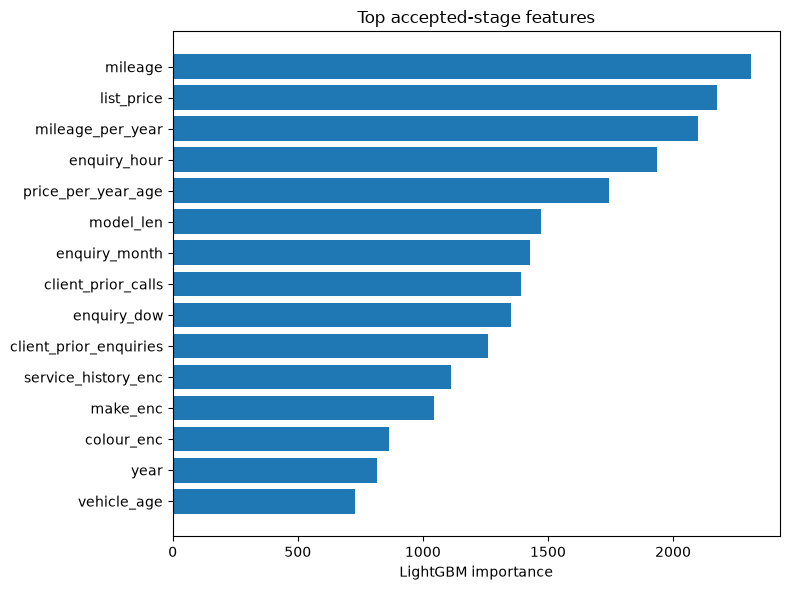

In [19]:
top_features = importance_table.head(15).iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("LightGBM importance")
plt.title("Top accepted-stage features")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Submission

In [23]:
submission = pd.DataFrame({
    "deal_ref": test_features["deal_ref"].values,
    "p_quote": np.clip(test_predictions["quote"], 0.0001, 0.9999),
    "p_prospect": np.clip(test_predictions["prospect"], 0.0001, 0.9999),
    "p_inspection": np.clip(test_predictions["inspection"], 0.0001, 0.9999),
    "p_accepted": np.clip(test_predictions["accepted"], 0.0001, 0.9999),
})

# Keep the required test row order.
submission = (
    submission
    .set_index("deal_ref")
    .loc[test_raw["deal_ref"].values]
    .reset_index()
)

sample_path = find_file("sample_submission.csv", SUBMISSION_DIRS)
sample_submission = pd.read_csv(sample_path)

expected_columns = list(sample_submission.columns)
submission = submission[expected_columns]

assert list(submission.columns) == expected_columns, "Column mismatch"
assert len(submission) == len(sample_submission), "Row count mismatch"
assert (
    submission["deal_ref"].astype(str).values
    == sample_submission["deal_ref"].astype(str).values
).all(), "deal_ref order mismatch"

probability_columns = ["p_quote", "p_prospect", "p_inspection", "p_accepted"]

assert np.isfinite(submission[probability_columns].values).all(), "Non-finite probabilities found"
assert ((submission[probability_columns] >= 0).all().all()), "Probability below zero found"
assert ((submission[probability_columns] <= 1).all().all()), "Probability above one found"

funnel_violations = {
    "p_prospect > p_quote": int((submission["p_prospect"] > submission["p_quote"]).sum()),
    "p_inspection > p_prospect": int((submission["p_inspection"] > submission["p_prospect"]).sum()),
    "p_accepted > p_inspection": int((submission["p_accepted"] > submission["p_inspection"]).sum()),
}

print("Submission checks passed.")
print("Funnel consistency check:", funnel_violations)

submission.to_csv("submission_final.csv", index=False)
print("Saved submission_final.csv")
submission.head()


Submission checks passed.
Funnel consistency check: {'p_prospect > p_quote': 13, 'p_inspection > p_prospect': 267, 'p_accepted > p_inspection': 1974}
Saved submission_final.csv


,deal_ref,p_quote,p_prospect,p_inspection,p_accepted
0,GW00048828,0.998633,0.336700,0.067045,0.086102
1,GW00476614,0.998633,0.640130,0.349648,0.306983
2,GW00525146,0.998633,0.005644,0.000871,0.000645
3,GW00526094,0.998633,0.004302,0.008210,0.003178
4,GW00526169,0.998633,0.363098,0.211066,0.096788


In [24]:
metadata = {
    "random_seed": RANDOM_SEED,
    "n_splits": N_SPLITS,
    "feature_count": len(feature_columns),
    "accepted_oof_composite": float(accepted_score),
    "accepted_oof_auc": float(accepted_auc),
    "accepted_oof_brier": float(accepted_brier),
    "accepted_oof_mean_precision_at_k": float(accepted_mean_pk),
    "models": {
        "quote": "base_rate",
        "prospect": "lightgbm",
        "inspection": "lightgbm",
        "accepted": "lightgbm_xgboost_catboost_performance_weighted_blend",
    },
    "hyperparameter_search": {
        "ran_optuna_search": bool(RUN_HYPERPARAM_SEARCH and OPTUNA_AVAILABLE),
        "n_trials": N_TRIALS,
        "best_lgb_params": BEST_LGB_PARAMS,
        "best_xgb_params": BEST_XGB_PARAMS,
        "best_cat_params": BEST_CAT_PARAMS,
    },
    "class_imbalance_handling": "is_unbalance (LightGBM) / scale_pos_weight (XGBoost) / auto_class_weights=Balanced (CatBoost)",
    "funnel_violations": funnel_violations,
}

with open("model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Saved model_metadata.json")


Saved model_metadata.json
